# Lab: Extreme Events-Jackson Haiz

## Modeling the Unusual

- For a given sample, the maximum and minimum are fixed
- But if we have a large number of samples, we can study the distribution/density of those max/min draws
- Imagine:
    - The biggest storm in a year
    - The worst loss for the market in a month
    - The biggest earthquake in a decade
    - The longest time between goals in a game
- This is how we understand the distribution/density of extreme events
- The **$k$-th order statistic** is the $k$-th largest value in a sample of $n$ from some distribution
- The minimum is the first order statistic and the maximum is the $n$-th order statistic

## Example: Drawing from a Gaussian

Below, we find the minimum of a sample of size n drawn from a normal distribution, and then repeat this b times, to get a distribution of the minimum with 10000 counts in it. This is the distribution of the 1st order statistic, shown below in blue.

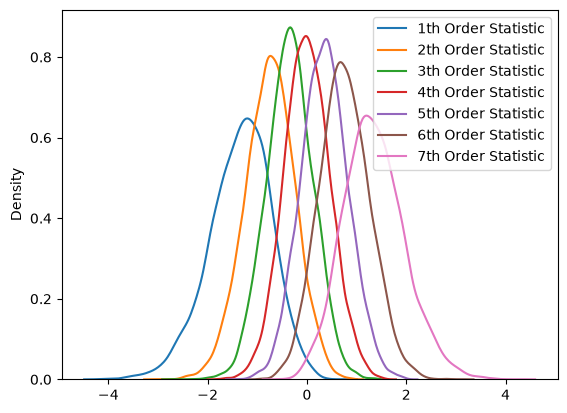

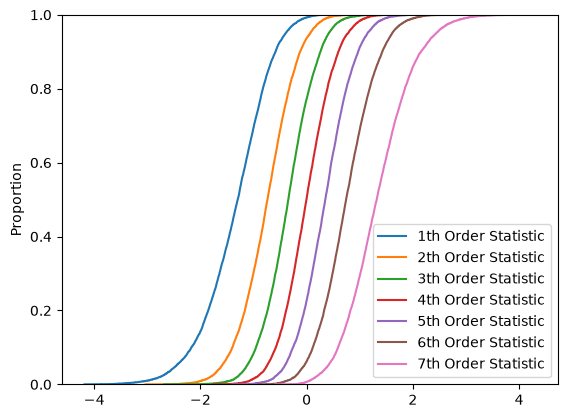

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

rng = np.random.default_rng( seed = 100 ) # Create a random number stream

n = 7 # Sample Size
b = 10_000 # Number of Simulations

sample = rng.standard_normal( size = (n,b) ) # Draw a sample from the standard normal distribution
sorted_sample = np.sort(sample, axis=0) # Sort each column (each simulated sample of size n)

for j in range(n): # For each rank
    sns.kdeplot( sorted_sample[j,:], label=f'{1+j}th Order Statistic') # Plot the KDE
plt.legend() # Add legend
plt.show()

for j in range(n): # For each rank
    sns.ecdfplot( sorted_sample[j,:], label=f'{1+j}th Order Statistic') # Plot the ECDF
plt.legend() # Add legend
plt.show()

## Analytic Relationship

### Maximum
If $F(x)$ is the underlying true CDF, let's consider the analytical equation for the distribution of the maximum of a sample of size $n$. (The maximum is its own random variable, with its distribution plotted above. What is this in math?) To build the CDF of the maximum, we ask (as always): "What's the probability the maximum lands at or below x?" for every x. In other words:
$$F_{max}(x) = P(X_{max} \leq x)$$

This is nothing new, just applying it to the distribution of a specific order statistic, the max.

So what is the **probability that all of the draws are less than or equal to $x$**, i.e. what is the probability that the maximum is less than or equal to $x$ (the right hand side)? Because each draw is independent:

$$P(X_1 \leq x \land ... \land X_n \leq x) = P( X_1 \leq x) \cdot P( X_2 \leq x ) \cdot ... \cdot  P( X_n \leq x)$$

Because we are pulling from the same distribution every time, **each of these probabilities equals our CDF, $F(x)$**:

$$P(X_1 \leq x, ..., X_n \leq x) = F(x) \cdot F(x) ... \cdot F(x)$$

The probability that all of the draws are less than or equal to x is therefore:

$$ F_{\max}(x) = F(x) \cdot F(x) \cdots F(x) = F(x)^n $$

What is its density?

Its density is:

$\frac{d}{dx}\left[F(x)^n\right] = nF(x)^{n-1}F'(x)$

We derived this in class.

## Minimum
The distribution of the minimum is somewhat harder, because our CDF is asking $\leq x$, and "max $\leq x$" means "all $\leq x$" but "min $\leq x$" does not mean "all $\leq x$". We can't just substitute in multiple copies of $F(x)$.  Instead of looking at the probability that all draws are less than or equal to $x$, we need to know the probability that at least one is.

We want to ask "is the minimum less than or equal to x?" which is the opposite of asking "are all of the draws, including the minimum, above x?" The probability that all observations are above $x$ is $(1-F(x))^{n}$. Because this is the opposite of the question we actually want to ask, the complementary probability is what we truly want:

$$ F_{min}(x) = 1 - (1-F(x))^n $$

What is its density?

The density is:

$f_{min}(x) = n(1-F(x))^{n-1}f(x)$

We also derived this in class.


## All of the other order statistics, generally
- If you're curious, the density of the $k$-th of $n$ order statistics is

$$
f_k(x) = \dfrac{n!}{(k-1)!(n-k)!} F(x)^{k-1} (1-F(x))^{n-k}f(x)
$$

- We'll use the results for the minimum and maximum

## The Data

We have three datasets:

1. Rainfall *totals* for every state-month from 1981 to 2025, with 5 reporting stations per state each month
2. Rainfall for every *station-day* over that same 1981-2025 period (same 5 stations per state) — much bigger, and used for a single question near the end of Step One
3. Daily and monthly U.S. stock market returns from 1926 to 2026

We want to understand tail behavior, to better reason about risk (engineering, financial, etc.).


In [2]:
df = pd.read_parquet("data/ghcn_prcp_monthly.parquet")
df.head()

,state,state_name,station_rank,station_id,station_name,latitude,longitude,elevation_m,year,month,month_start,prcp_total_mm,observed_total_mm,observed_days,days_in_month,coverage_fraction,prorated,imputed
0,AK,Alaska,1,USW00027502,BARROW AP,71.2869,-156.7394,8.2,1981,1,1981-01-01,5.900001,5.900001,31,31,1.0,False,False
1,AK,Alaska,1,USW00027502,BARROW AP,71.2869,-156.7394,8.2,1981,2,1981-02-01,1.600000,1.600000,28,28,1.0,False,False
2,AK,Alaska,1,USW00027502,BARROW AP,71.2869,-156.7394,8.2,1981,3,1981-03-01,0.900000,0.900000,31,31,1.0,False,False
3,AK,Alaska,1,USW00027502,BARROW AP,71.2869,-156.7394,8.2,1981,4,1981-04-01,5.100000,5.100000,30,30,1.0,False,False
4,AK,Alaska,1,USW00027502,BARROW AP,71.2869,-156.7394,8.2,1981,5,1981-05-01,1.700000,1.700000,31,31,1.0,False,False


**Step One.** 
1. Plot the ECDF and KDE of `prcp_total_mm` with seaborn— the distribution and density of rainfall across the entire U.S.

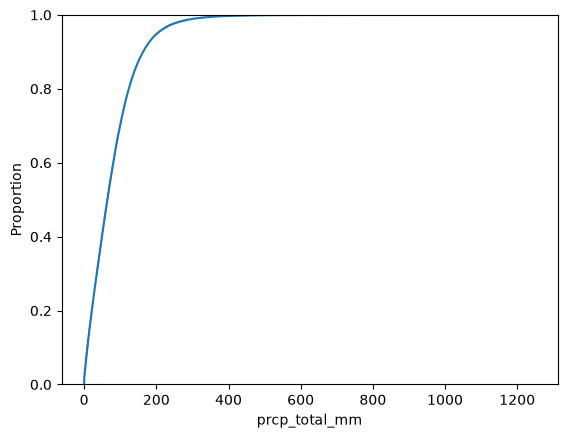

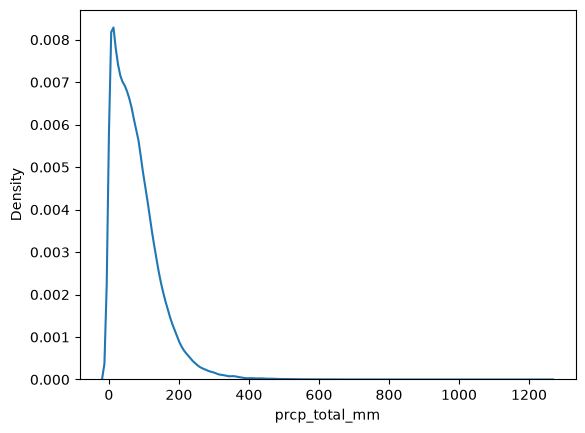

In [5]:
sns.ecdfplot(df,x='prcp_total_mm')
plt.show()
sns.kdeplot(df,x='prcp_total_mm')
plt.show()

2. Now group by year-month and compute the **median** and **maximum** precipitation nationwide. Plot the ECDF and KDE of these two statistics.

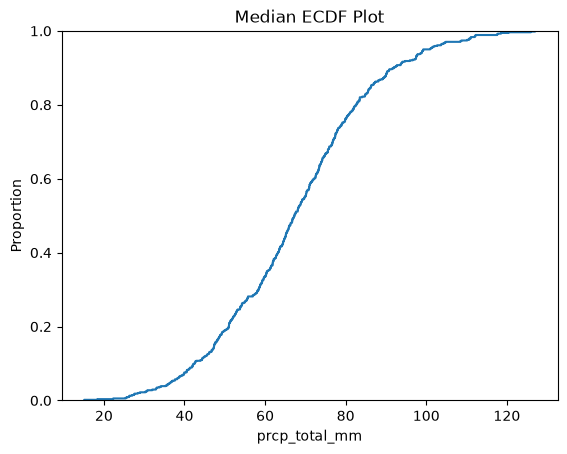

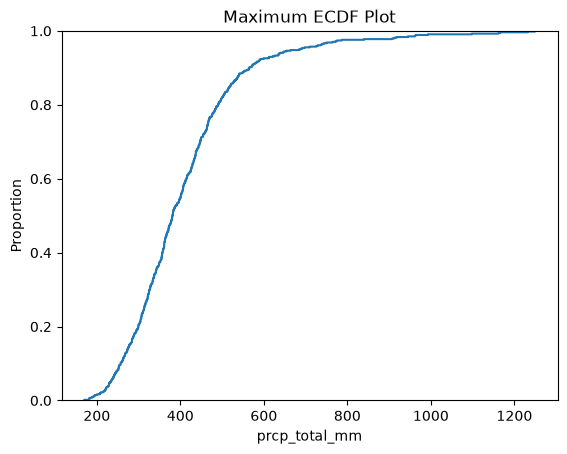

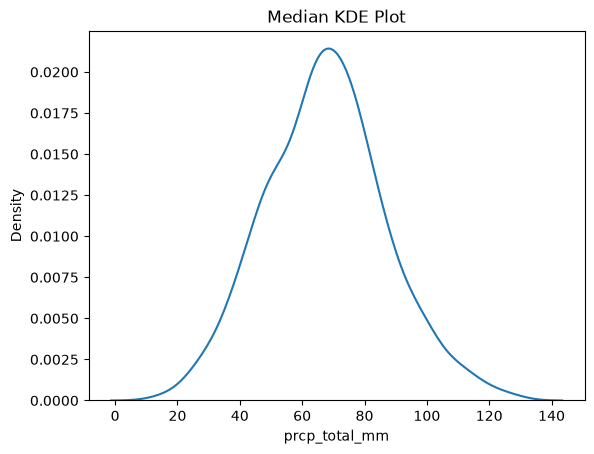

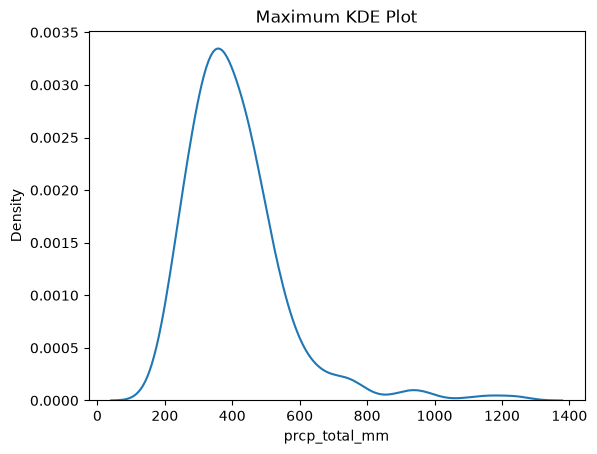

In [ ]:
# Computing Statistics
median=df.groupby(["year", "month"])["prcp_total_mm"].median()
max=df.groupby(["year", "month"])["prcp_total_mm"].max()

#Plotting KDE & ECDF for these two statistics
sns.ecdfplot(median)
plt.title('Median ECDF Plot')
plt.show()

sns.ecdfplot(max)
plt.title('Maximum ECDF Plot')
plt.show()

sns.kdeplot(median)
plt.title('Median KDE Plot')
plt.show()

sns.kdeplot(max)
plt.title('Maximum KDE Plot')
plt.show()


3. How do your results in part 2 compare to your results in part 1?

Our results are completely different between parts 1 and 2. In part one, we are looking at the raw KDE and ECDF plots of the data, whereas in part two we are first tranforming the data into a metric and then plotting off that basis. Our part 1 results are not giving us much information, because the data is effectively drowning itself out. By grouping by median, and max, we are able to make more use of the data by plotting the proportion and density of average (median) rainfall and maximum values, which gives us more information on both average and extreme rainfall totals. For example part 1's KDE plot tells us that most rainfall per month is centered between 0-200 MM of total preciptation, with the peak being slightly above zero total mm of precipitation. In part 2, the median KDE plot tells us that the **average** total of rainfall per month is much more dynamic, with nearly all values being centered between 20, and 120 mm of total precipation, with a peak of around 65 MM of rainfall. The maximum communicates a similar message showing us the **maximum** of rainfall per month, i.e extreme events. The peak of the maximum is slightly less than 400 MM of total rainfall per month, telling us that most maximum rainfalls are 400 MM of total rain. The ECDF is communicating the same thing in a different message. All in all, the results are different across the parts because we are leaning into new facets of the data, which can potentially explain extreme events and averages better than just using the ordinary, unchanged data.

<div class="alert alert-info">Compare and contrast the ECDFs and KDEs from parts 1 and 2. Explain why they are different:</div>

They are diffferent because they are communicating new insights based off metrics of the data. In part 1 we are merely looking at the distributions of the raw, unchanged data. In part 2 we are comptuing the medians and maximums of rainfall and distrubuting off based on that. The ECDF and KDE's for the median and maximum values are telling us the proportions and density of the average and largest values in X at each month and year of the data. So it looks different because the distriubtions we are looking at are based on essentially different but related data.

The ECDF and KDE plots for part 1 are plotting the distribution and denisity of the data in its enitrerity.

The ECDF and KDE plots for part 2 are plotting the distrubitions and density for the average and maximum values in the data.

For example part 1's KDE plot tells us that the highest concentration of rainfall per month is centered between 0-200 MM of total preciptation, with the peak being slightly above zero total mm of precipitation. In part 2, the median KDE plot tells us that the **average** total of rainfall per month is much more dynamic, with nearly all values being centered between 20, and 120 mm of total precipation, with a peak of around 65 MM of rainfall. The maximum communicates a similar message showing us the **maximum** of rainfall per month, i.e extreme events. (used from last question, but it is getting at what im saying)


4. Now define a state's rainfall differently: take the **median** of the 5 stations in each month, then find the **maximum** across the state's 12 months in a year — the "wettest month." For each state, what's the expected value of the wettest month? Plot the ECDF of Virginia's annual maxima (the wettest month in each of the 45 years), and overlay the analytical prediction $F_{\max}(x) = \hat F(x)^{12}$.

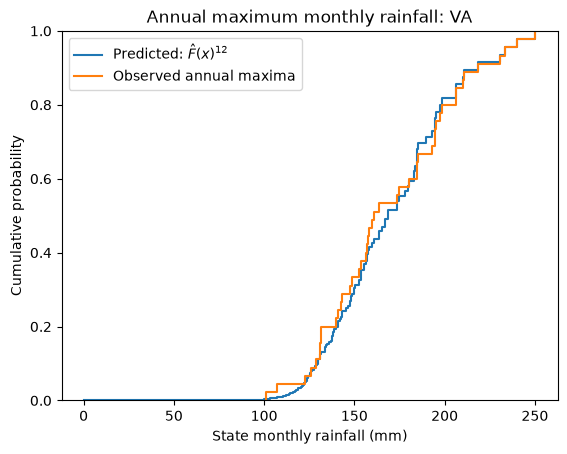

In [34]:
# One rainfall value per state-month: median of the stations
state_month = (
    df.groupby(["state", "year", "month"], as_index=False)
      .agg(prcp_total_mm=("prcp_total_mm", "median"))
)

# Wettest month for each state-year
state_year_max = (
    state_month.groupby(["state", "year"], as_index=False)
               .agg(prcp_total_mm=("prcp_total_mm", "max"))
)


exp_wettest = state_year_max.groupby("state", as_index=False).agg(E_wettest_month=("prcp_total_mm", "mean"))
exp_wettest.loc[exp_wettest["state"] == "VA"]


state = "VA"

levels = (
    state_month.loc[state_month["state"] == state, "prcp_total_mm"]
    .to_numpy()
)

observed_max = (
    state_year_max.loc[state_year_max["state"] == state, "prcp_total_mm"]
    .to_numpy()
)

x = np.sort(np.unique(levels))
F_hat = np.searchsorted(np.sort(levels), x, side="right") / len(levels)

plt.step(
    x,
    F_hat**12,
    where="post",
    label=r"Predicted: $\hat F(x)^{12}$"
)

sns.ecdfplot(x=observed_max,
    label="Observed annual maxima")

plt.xlabel("State monthly rainfall (mm)")
plt.ylabel("Cumulative probability")
plt.title(f"Annual maximum monthly rainfall: {state}")
plt.legend()
plt.show()

<div class="alert alert-info">How close is the fit here? If it differs from question 4's fit, why:</div>

The fit is pretty close, however it differents because the formula $\hat F(x)^{12}=F_{max}(x)$ prediction assumes that all observations are I.I.D, when reality they are not. The data is neither independent or identically distributed, for weather patterns do not remain constant across months nor do patterns  remain independent of other months.

5. **A question for FEMA.** So far you've worked with *monthly* rainfall totals. Switch now to the daily station-level file (`ghcn_prcp_daily.parquet`) — reload `df` from it, and don't mix it with the monthly data above.

   A day with more than 120mm of rain is a serious flood/landslide risk. On any single station-day, that's rare. But a state doesn't get one chance a month — it gets 5 stations $\times$ (days in the month) chances. FEMA doesn't care about the average day, or the single worst day on record; it cares about the probability that *some* station has a disaster day at some point during the month.

   For each state-month, estimate
   $$P(\text{at least one station-day exceeds 120mm}) = 1 - \hat F(120)^n$$
   where $\hat F$ is the empirical CDF of a single station-day's rainfall for that state and calendar month (pooled across all years), and $n$ is the number of station-days in one occurrence of that month (5 stations $\times$ days in the month). Report the 20 highest-risk state-months.


,state,month,p_any_station_day_exceeds_120mm
122,HI,3,0.387166
104,FL,9,0.373367
130,HI,11,0.359242
208,LA,5,0.359229
131,HI,12,0.344789
121,HI,2,0.330060
105,FL,10,0.330026
476,SC,9,0.299512
207,LA,4,0.299512
319,NC,8,0.283726


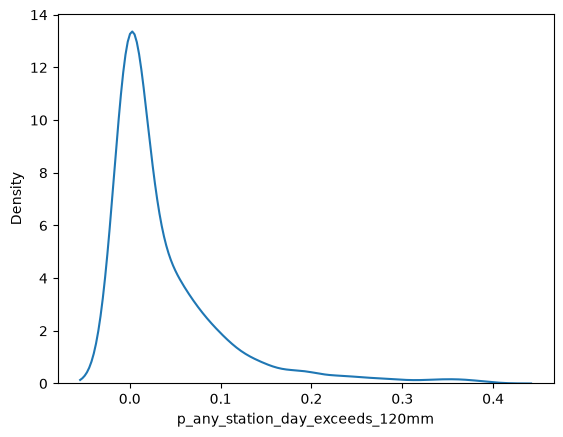

In [35]:
# Fresh load -- this question uses only the daily file, not the monthly one above.
#df_daily = pd.read_parquet("data/ghcn_prcp_daily.parquet")

url = (
    "https://www.dropbox.com/scl/fi/"
    "pjmyop3fqjdy8oabkc4ab/ghcn_prcp_daily.parquet"
    "?rlkey=otxenczb3pxgzz53kc1i5zxww&dl=1"
)
df_daily = pd.read_parquet(url)
df_daily = df_daily.loc[df_daily["observed"]]

threshold = 120  # mm in a single day

def disaster_risk(group):
    F_hat = (group["prcp_mm"] <= threshold).mean()
    n = len(group) / group["year"].nunique()  # station-days in one year's occurrence of this month
    return 1 - F_hat**n

risk = (
    df_daily.groupby(["state", "month"])
            .apply(disaster_risk, include_groups=False)
            .rename("p_any_station_day_exceeds_120mm")
            .reset_index()
            .sort_values("p_any_station_day_exceeds_120mm", ascending=False)
)

sns.kdeplot(risk['p_any_station_day_exceeds_120mm'])

risk.head(20)

<div class="alert alert-info">Which states and months face the most risk of a greater-than-120mm day? How high is the probability? Among all state-months, describe the density of high precipitation days:<div>

States like Hawaii and Florida, in months like March and September, face the most risk of a greater than 120 mm day. For example, Hawaii's greatest risk of a greater than 120 mm day is in march at probability 0.387166, and Florida's greatest risk is in september at probability .373367.

Among all states-months, the highest concentration of high precipitation days lies just around probability zero, i.e its peak is around probability zero. This means that both Florida and Hawaii, in months like March and September, are vastly in the extreme when concerning the probability for a greater than 120 mm day, for the highest concentration of states have around a zero percent probability of their state having a greater than 120 mm day of precipitation in any given month.

**Step Two.**

Our second data set is daily and monthly U.S. stock market returns. Instead of storms across space (five stations in a state) or across the calendar (twelve months in a year), the "sample" is the set of trading days within a month, and we ask about the best and worst day in that sample.

In [36]:
df = pd.read_parquet("data/ff_market_daily.parquet")

print(f"{len(df):,} trading days")
print(f"{df['date'].min().date()} through {df['date'].max().date()}")
df.head()

26,296 trading days
1926-07-01 through 2026-07-31


,date,year,month,month_start,trading_day_of_month,mkt_excess_return_pct,risk_free_return_pct,market_return_pct,absolute_market_return_pct
0,1926-07-01,1926,7,1926-07-01,1,0.09,0.01,0.10,0.10
1,1926-07-02,1926,7,1926-07-01,2,0.45,0.01,0.46,0.46
2,1926-07-06,1926,7,1926-07-01,3,0.17,0.01,0.18,0.18
3,1926-07-07,1926,7,1926-07-01,4,0.09,0.01,0.10,0.10
4,1926-07-08,1926,7,1926-07-01,5,0.22,0.01,0.23,0.23


1. Plot the KDE and ECDF of daily market returns.

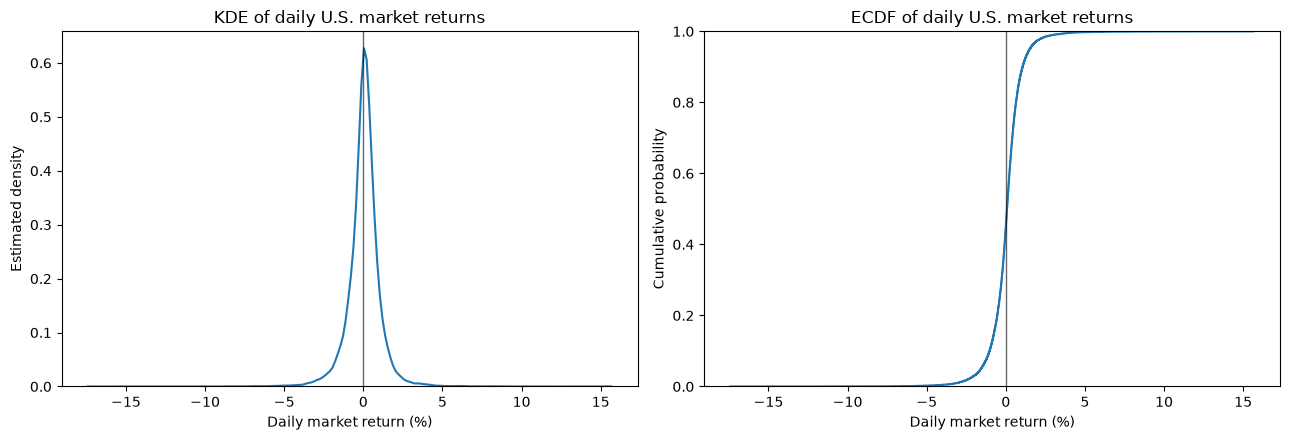

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.kdeplot(
    data=df,
    x="market_return_pct",
    cut=0,
    ax=axes[0],
)
axes[0].axvline(0, color="black", linewidth=1, alpha=0.6)
axes[0].set(
    title="KDE of daily U.S. market returns",
    xlabel="Daily market return (%)",
    ylabel="Estimated density",
)

sns.ecdfplot(
    data=df,
    x="market_return_pct",
    ax=axes[1],
)
axes[1].axvline(0, color="black", linewidth=1, alpha=0.6)
axes[1].set(
    title="ECDF of daily U.S. market returns",
    xlabel="Daily market return (%)",
    ylabel="Cumulative probability",
)

plt.tight_layout()
plt.show()

2. For each calendar month, compute the **best** (max) and **worst** (min) daily return — the first and $n$-th order statistics of that month's trading days. Plot the KDE of the monthly best and worst returns, overlaid.

In [38]:
monthly = (
    df.groupby(["year", "month"], as_index=False)
         .agg(
             month_start=("month_start", "first"),
             trading_days=("date", "size"),
             worst_return_pct=("market_return_pct", "min"),
             best_return_pct=("market_return_pct", "max"),
             median_return_pct=("market_return_pct", "median"),
         )
)

# Put losses and gains on the same positive-magnitude scale.
monthly["worst_loss_pct"] = -monthly["worst_return_pct"]

print(f"{len(monthly):,} calendar months")
print(
    f"Trading days per month: {monthly['trading_days'].min()} "
    f"to {monthly['trading_days'].max()}"
)
monthly.head()

1,201 calendar months
Trading days per month: 15 to 27


,year,month,month_start,trading_days,worst_return_pct,best_return_pct,median_return_pct,worst_loss_pct
0,1926,7,1926-07-01,25,-0.72,1.10,0.18,0.72
1,1926,8,1926-08-01,26,-1.39,0.85,0.32,1.39
2,1926,9,1926-09-01,24,-0.98,0.91,-0.03,0.98
3,1926,10,1926-10-01,25,-1.81,1.53,-0.09,1.81
4,1926,11,1926-11-01,24,-0.62,0.67,0.19,0.62


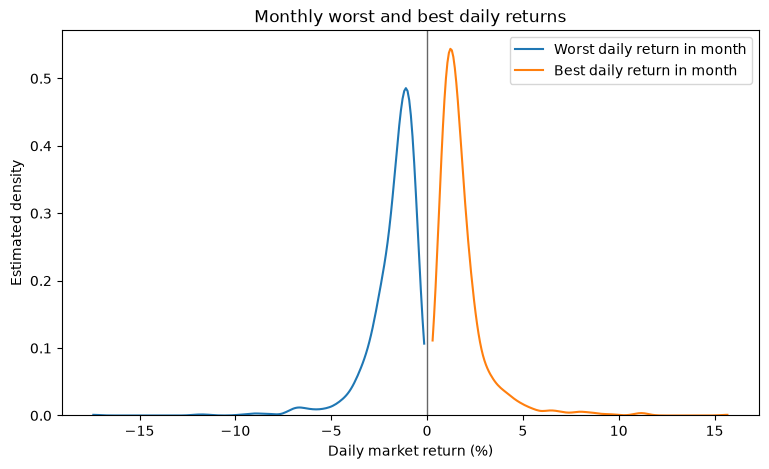

In [39]:
plt.figure(figsize=(9, 5))
sns.kdeplot(
    x=monthly["worst_return_pct"],
    label="Worst daily return in month",
    cut=0,
)
sns.kdeplot(
    x=monthly["best_return_pct"],
    label="Best daily return in month",
    cut=0,
)
plt.axvline(0, color="black", linewidth=1, alpha=0.6)
plt.xlabel("Daily market return (%)")
plt.ylabel("Estimated density")
plt.title("Monthly worst and best daily returns")
plt.legend()
plt.show()

<div class="alert alert-info">Describe the symmetry (or lack of it) between the best- and worst-day densities. Compare them to the overall populations of daily returns. Use code as appropriate to make these comparisons, and then write out your answer in a markdown cell.</div>

In [42]:
ecdf_value_50 = df["market_return_pct"].median()

ecdf_value_50

np.float64(0.08)

In [43]:
kde_line = axes[0].lines[0]

x_values = kde_line.get_xdata()
density_values = kde_line.get_ydata()

max_index = density_values.argmax()

x_at_max_density = x_values[max_index]
max_density = density_values[max_index]

print(f"Maximum density: {max_density:.4f}")
print(f"Occurs at return: {x_at_max_density:.4f}%")

Maximum density: 0.6272
Occurs at return: 0.0443%


While the best and worst day densities are relative to eachother, they are not symmetrical. This is because it appears that,  the density that the market performs well in the stock market is higher than the percentatge that the market performs poorly, speaking in terms of extremes. This intuitively makes sense because index funds have historically leaned positively, and while mapping extremes to averages is not neccesairly apples to apples, it provides backing on why they are not symmetrical as the market in totality leans positively even in extremes.

Comparing this to the overall population of daily returns and this affirms my earlier statement. The median of returns is is .08, meaning the overall market historically leans positively. Additionally the highest concentration of returns (.6272) is at a.0443% daily market return, which futhermore provides emphasis that the market leans postitively.

The difference between these two densities is what we are mapping. For the first KDE, we are mapping the density of **all** daily returns, whereas in the second KDE we are mapping the density of just the **minimum** and **maxiumum** daily returns for each month. However both these densities effectively explain the other. On average the market performs positively, which can be partly attributed to the fact that the best returns occur with a higher density than the worst returns. 

3. Losses and gains are on opposite sides of zero, which makes them hard to compare directly. Put them on the same scale by looking at the *magnitude* of the worst loss (`-worst_return_pct`) against the magnitude of the best gain (`best_return_pct`). Plot both the KDE and ECDF.

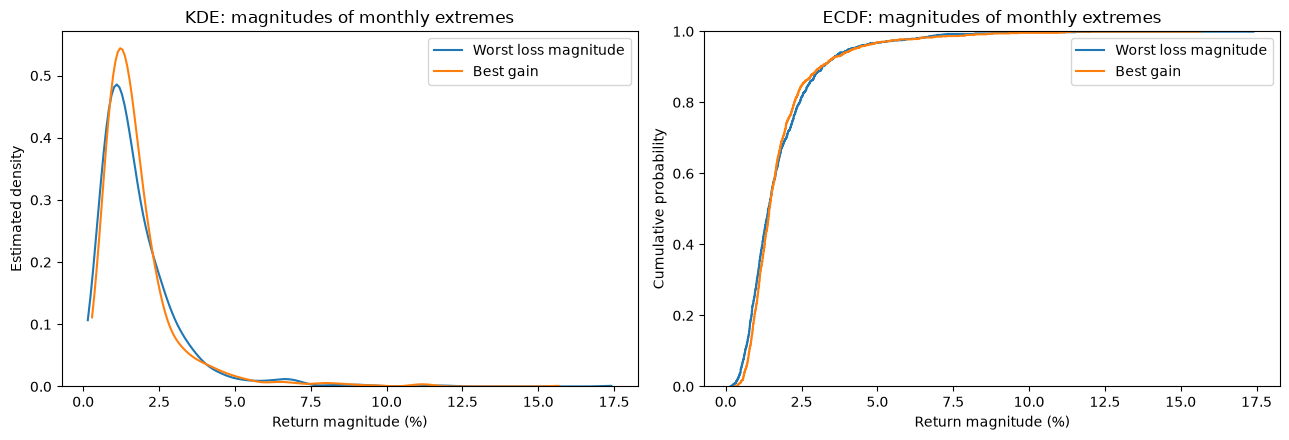

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.kdeplot(
    x=monthly["worst_loss_pct"],
    label="Worst loss magnitude",
    cut=0,
    ax=axes[0],
)
sns.kdeplot(
    x=monthly["best_return_pct"],
    label="Best gain",
    cut=0,
    ax=axes[0],
)
axes[0].set(
    title="KDE: magnitudes of monthly extremes",
    xlabel="Return magnitude (%)",
    ylabel="Estimated density",
)
axes[0].legend()

sns.ecdfplot(
    x=monthly["worst_loss_pct"],
    label="Worst loss magnitude",
    ax=axes[1],
)
sns.ecdfplot(
    x=monthly["best_return_pct"],
    label="Best gain",
    ax=axes[1],
)
axes[1].set(
    title="ECDF: magnitudes of monthly extremes",
    xlabel="Return magnitude (%)",
    ylabel="Cumulative probability",
)
axes[1].legend()

plt.tight_layout()
plt.show()

<div class="alert alert-info">Are large losses more extreme than large gains, or about the same:</div>

They are about the same. The ECDF tells us that the proportion of extremes at each return magintude is about the same. It is just that the best gains occur noticeably more than the large losses, as indicated through the KDE. At higher return magintudes however, [2.5-5.0] large losses occur slighty more than large gains, but in my opinion it isnt enough to say that large losses are more extreme than large gains as the difference is rather marginal.

4. Compute the median, 75th, 90th, 95th, and 99th percentile of both magnitudes from question 3. In what fraction of months does the worst loss exceed the best gain in magnitude?

In [45]:
tail_summary = pd.DataFrame(
    {
        "Worst loss magnitude": monthly["worst_loss_pct"],
        "Best gain": monthly["best_return_pct"],
    }
).quantile([0.50, 0.75, 0.90, 0.95, 0.99]).T

tail_summary.columns = ["median", "75%", "90%", "95%", "99%"]

print(
    "Fraction of months in which the worst loss exceeded the best gain: "
    f"{(monthly['worst_loss_pct'] > monthly['best_return_pct']).mean():.1%}"
)
tail_summary.round(2)

Fraction of months in which the worst loss exceeded the best gain: 44.8%


,median,75%,90%,95%,99%
Worst loss magnitude,1.41,2.21,3.18,4.06,6.97
Best gain,1.44,2.04,3.12,4.21,7.93


<div class="alert alert-info">What does this tail comparison say about the risk of losses vs. gains:</div>

This tail comparison suggests that the risk of losses vs. gains is close, but leans in the favor of gains as pertaining to extremes. This statment is supported the fraction of months in which the worst loss exceeded the best gain: 44.8% and the Median of the two extremes which is 1.41 for the worst loss magnitude and 1.44 for the best gain.

5. Plot the monthly best and worst daily returns over time. Do the extremes look stable across this ~100-year history, or are there periods where they're much larger? Can you identify any famous market events?

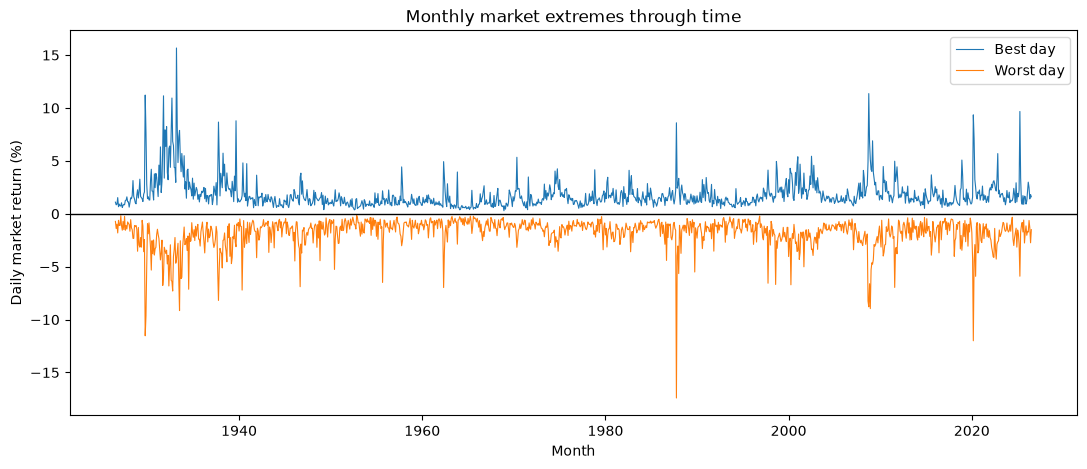

In [46]:
plt.figure(figsize=(13, 5))
plt.plot(
    monthly["month_start"],
    monthly["best_return_pct"],
    linewidth=0.8,
    label="Best day",
)
plt.plot(
    monthly["month_start"],
    monthly["worst_return_pct"],
    linewidth=0.8,
    label="Worst day",
)
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Month")
plt.ylabel("Daily market return (%)")
plt.title("Monthly market extremes through time")
plt.legend()
plt.show()

<div class="alert alert-info">Do upside and downside risk tend to go together (volatility), or does the market exhibit distinct periods in which the good shocks are concentrated and the bad shocks are concentrated? What implication does this have for investing?:</div> 

Upside and downside risks tend to go together, the graph suggests. The implication that this has for investing is that volatility does not strictly go in one direction. A percpetion that the market may be performing well is not exactly true because it is historically accurate to conclude that periods of large winnings are occuring at the same time as periods of large losses. The implication that is that the market may perform one way or the other, but always leads to steady growth. This is why I prefer mutual and index funds.

## Wrap-up



<div class="alert alert-info">This week has focused on kernel density estimation, particularly estimating the PDF from data. This lab takes that a step further: We can estimate and quantify the densities and distributions of random variables that build off of observed phenomena. What is the difference between the ECDF and KDE? Explain how these estimations today give us different information than an ECDF or KDE plot of the underlying data, but quantify information about the behavior of a different random variable.</div>

The ECDF tells us the proporiton of the sample that lies below a specific value.
The KDE tells us the how values are concentrated in a sample.

The estimations completed give us fundamentally different information than a ECDF or KDE plot of the underlying the data because we are transforming the data and therefore transforming the interpreation.

For example, in the lab today we transformed the data to survey metrics such as max values and medians. Thorugh the KDE and ECDF Plots we are able to observe variation in extreme and average values. This becomes very useful when navigating complexities and nuances in the data.


# I would like to acknowledge the use of CHATGPT as aid in completing this assignment. It was of particular aid in helping brainstorm ways to write the code and formatting my markdown into LateX format.